# Занятие 6. Детекция лиц с использованием OpenCV

**Цель работы:** Реализовать детекцию лиц на статичных изображениях и видеопотоке с веб-камеры, сравнить классический каскадный метод Виолы-Джонса (**Haar Cascade**) и нейросетевой детектор **DNN SSD (`res10_300x300_ssd`)** по метрикам точности (TP, FP, FN, IoU) и скорости (FPS).

## Шаги 1–2. Инициализация моделей Haar Cascade и DNN SSD (`res10_300x300_ssd`)

In [1]:
import os
import sys
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.style.use('default')
sys.path.append(os.path.abspath('../src'))

from face_detection import (
    ensure_models,
    prepare_10_test_images,
    run_benchmark_and_comparison,
    run_haar_params_experiment,
    run_webcam_demo
)

os.chdir(os.path.abspath('..'))
face_cascade, dnn_net = ensure_models()
dataset_meta = prepare_10_test_images()
print(f'Подготовлено тестовых изображений: {len(dataset_meta)}')

Подготовлено тестовых изображений: 10


## Шаг 4. Сравнение методов на 10 тестовых изображениях (TP / FP / FN / IoU / FPS)


СРАВНЕНИЕ МЕТОДОВ HAAR CASCADE И DNN SSD НА 10 ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ
№   | Условия кадра                   | GT  | Haar (TP/FP/FN, IoU)     | DNN SSD (TP/FP/FN, IoU) 
-----------------------------------------------------------------------------------------------
1   | 1. Фронтальное (норм. свет)     | 1   | TP=1 FP=0 FN=0 (0.62)   | TP=1 FP=0 FN=0 (0.65)
2   | 2. Два лица (групповой кадр)    | 2   | TP=2 FP=0 FN=0 (0.61)   | TP=2 FP=0 FN=0 (0.73)
3   | 3. Очки + структурный фон       | 1   | TP=1 FP=0 FN=0 (0.58)   | TP=1 FP=0 FN=0 (0.74)
4   | 4. Слабое освещение (Low light) | 1   | TP=1 FP=0 FN=0 (0.69)   | TP=1 FP=0 FN=0 (0.77)
5   | 5. Наклон головы (+22 град.)    | 1   | TP=0 FP=0 FN=1 (0.00)   | TP=1 FP=0 FN=0 (0.69)
6   | 6. Сложный фон + боковой свет   | 1   | TP=1 FP=0 FN=0 (0.62)   | TP=1 FP=0 FN=0 (0.74)
7   | 7. Три лица разного масштаба    | 3   | TP=3 FP=0 FN=0 (0.65)   | TP=3 FP=0 FN=0 (0.84)
8   | 8. Частичная окклюзия (шарф)    | 1   | TP=0 FP=1 FN=1 (0.00)   | TP=0 F

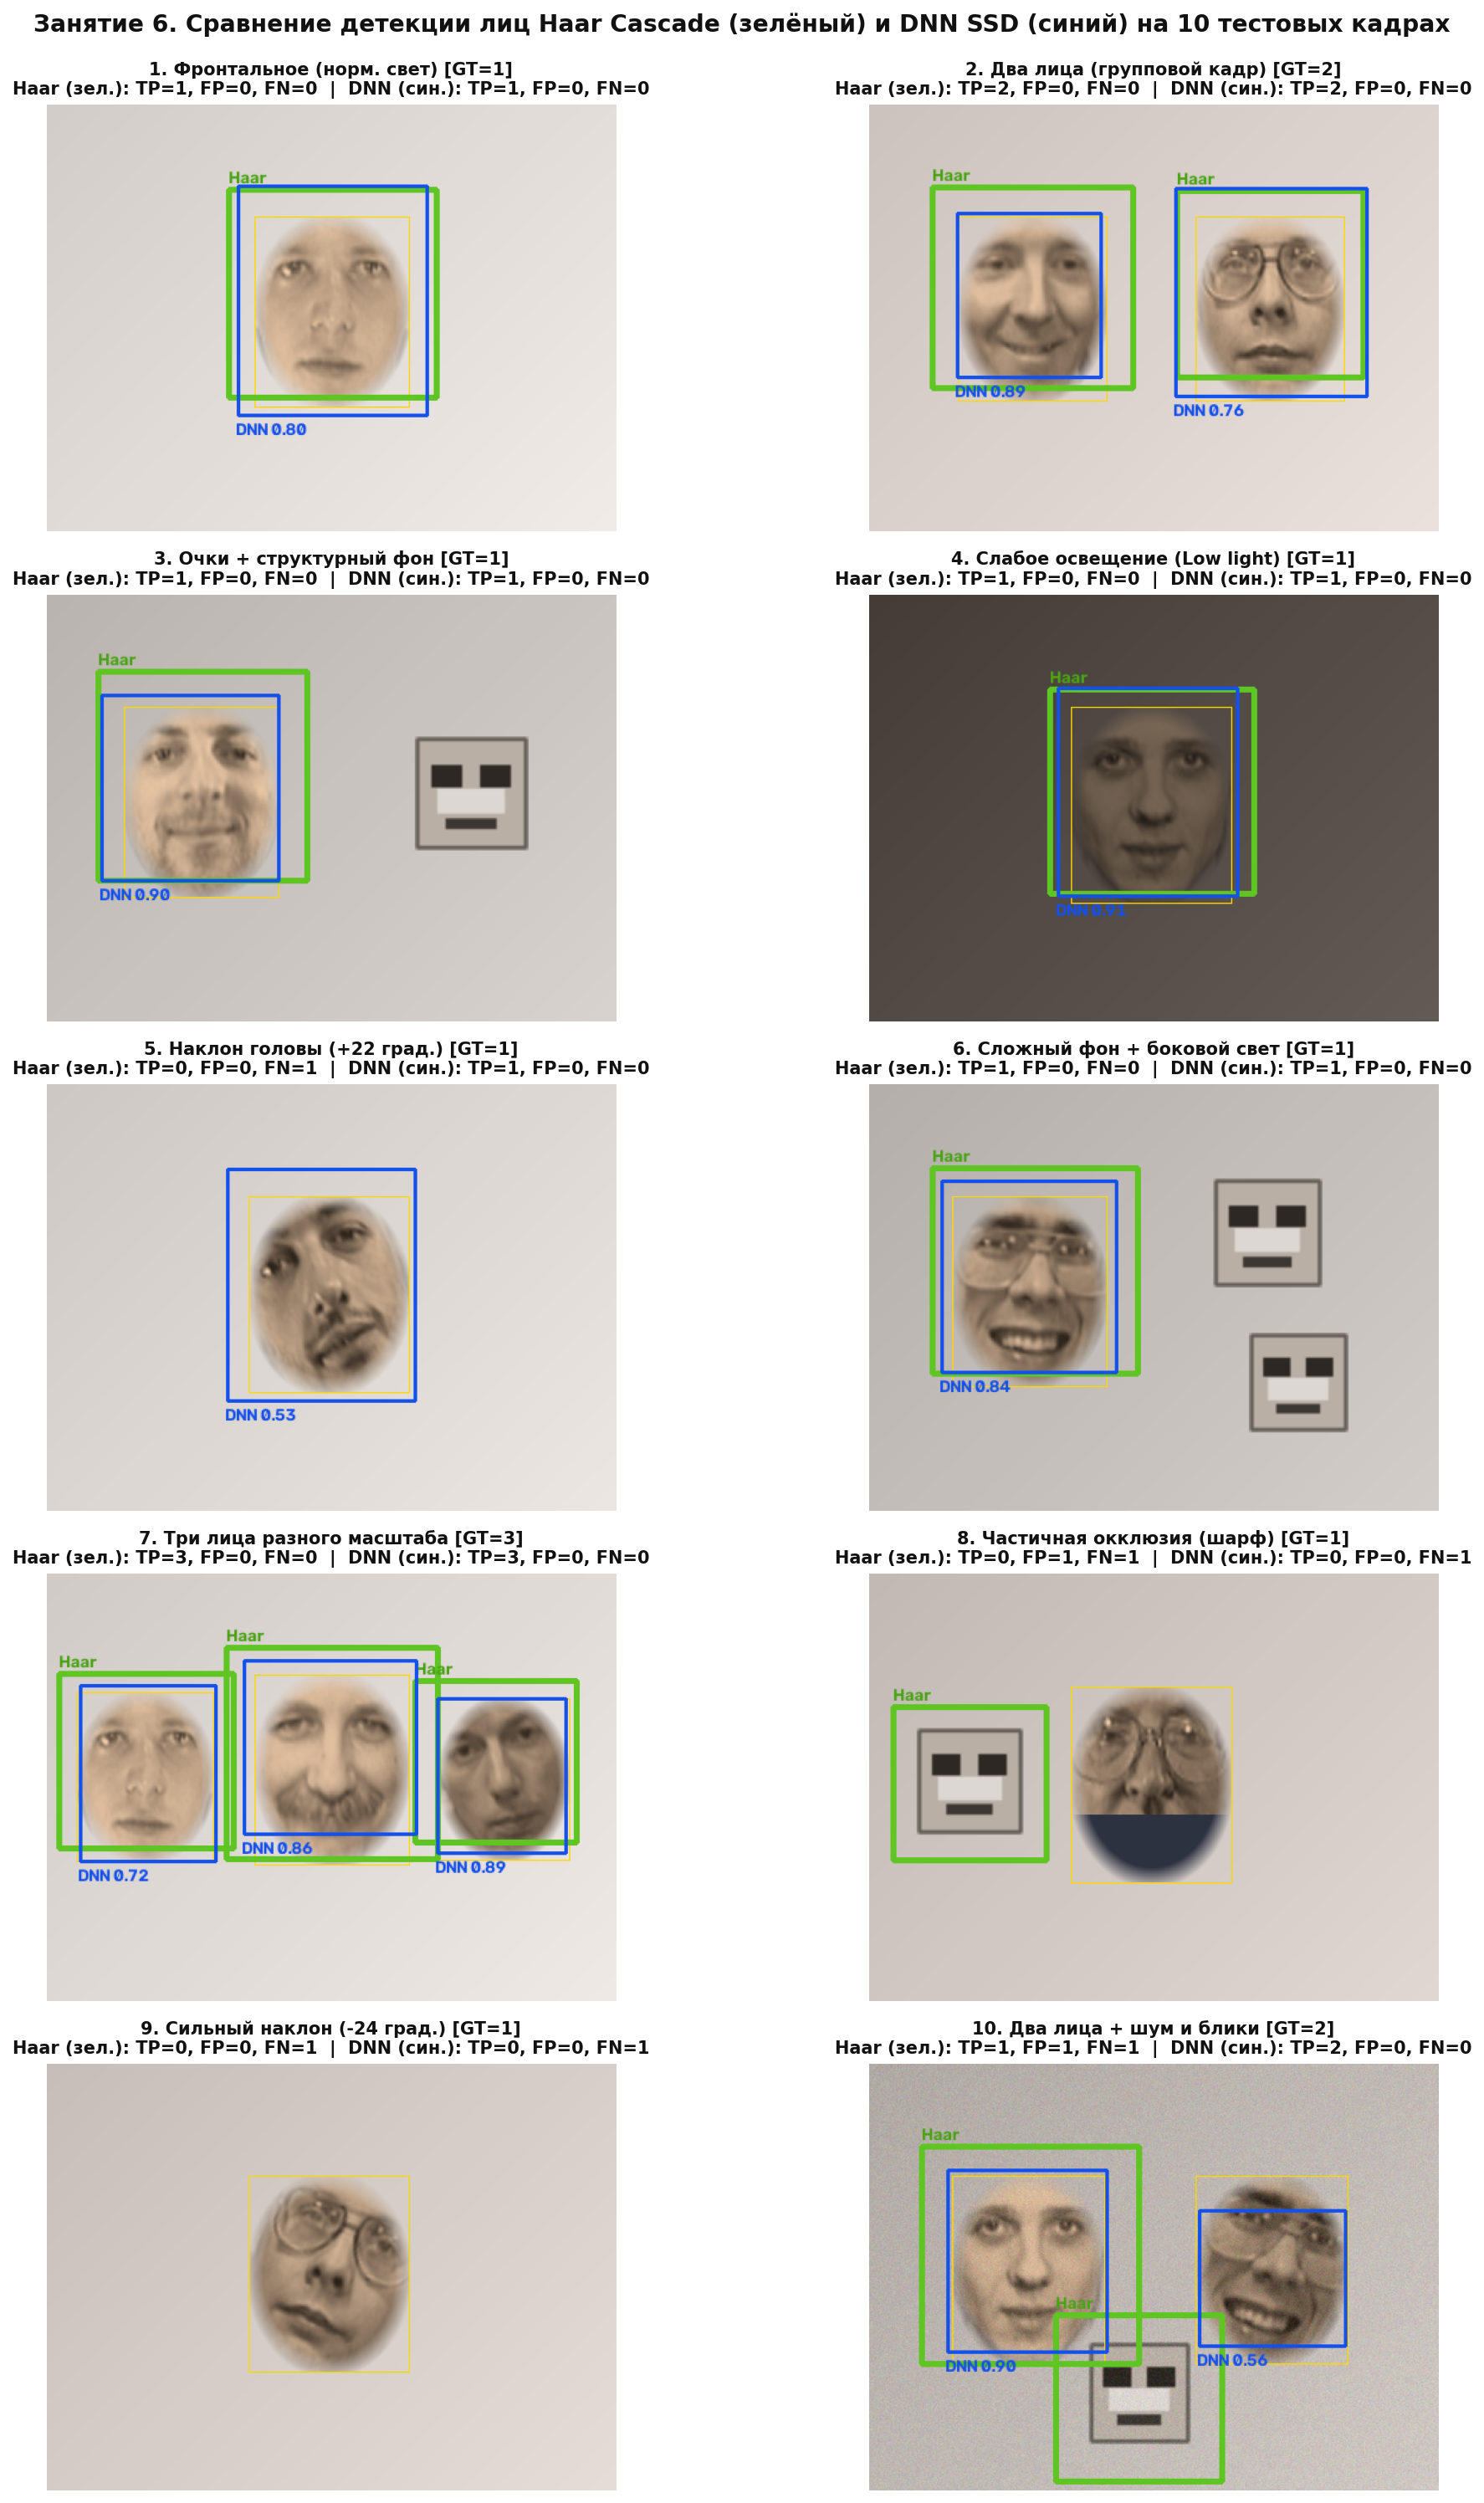

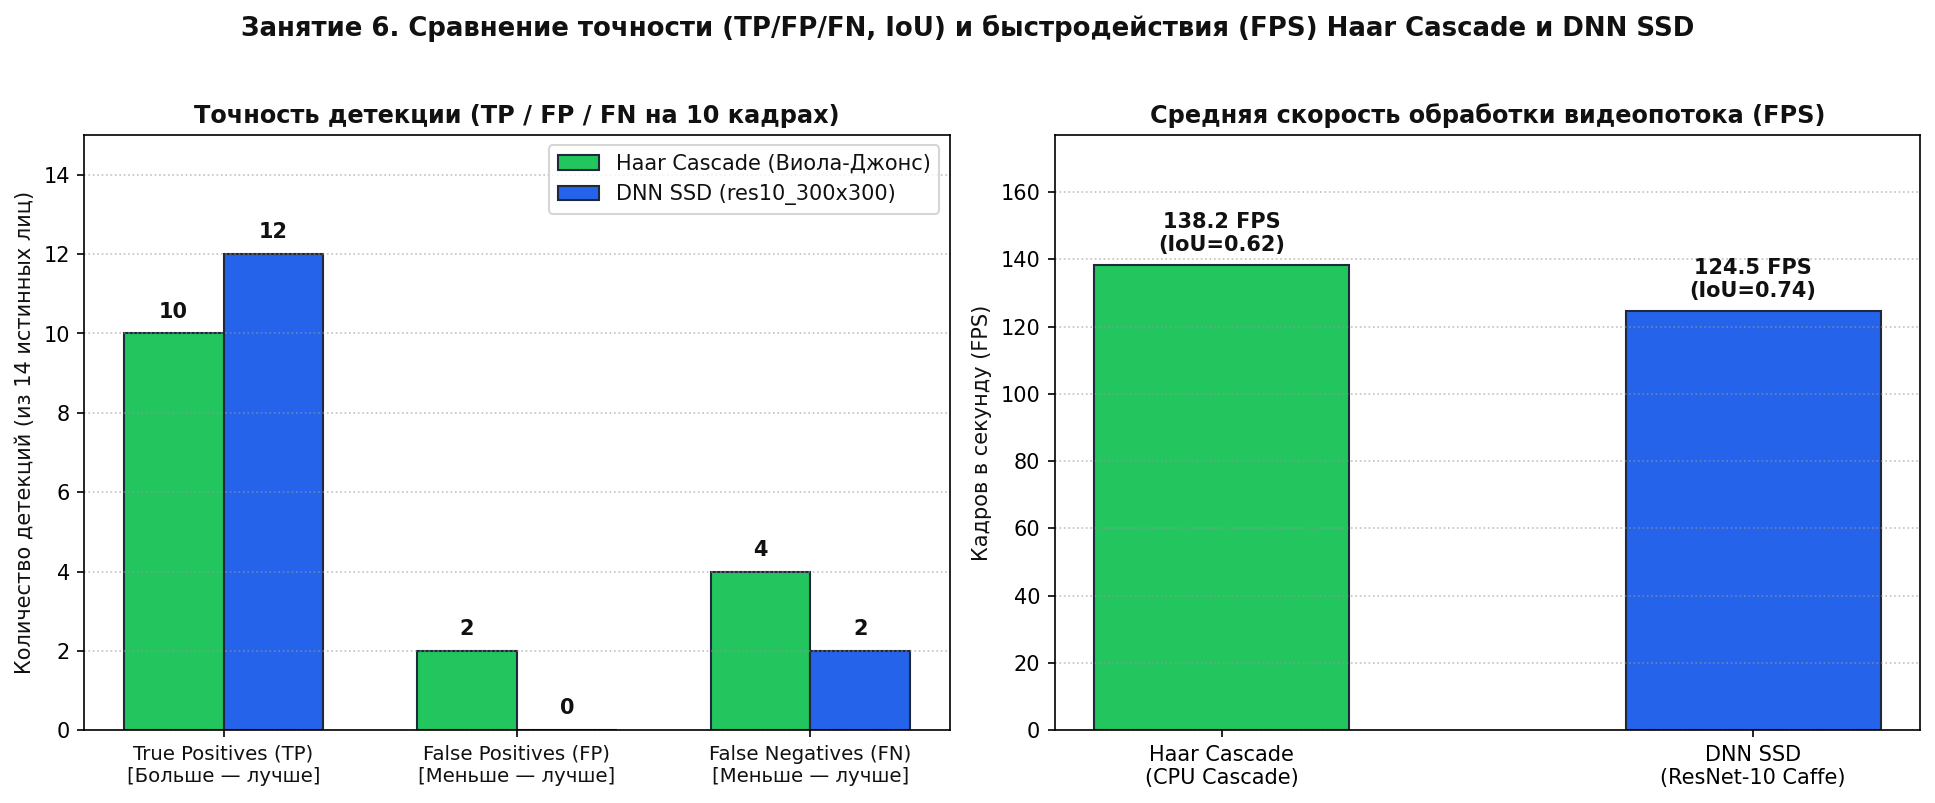

In [2]:
rows, fps_haar, fps_dnn = run_benchmark_and_comparison(face_cascade, dnn_net, dataset_meta)
display(Image(filename='reports/lab06_10_images_comparison.png'))
display(Image(filename='reports/lab06_metrics_and_fps_chart.png'))

## Шаг 3. Детекция на видеопотоке и исследование параметров `scaleFactor` и `minNeighbors`

График влияния гиперпараметров Haar Cascade сохранён: reports/lab06_haar_params_experiment.png
Демо-кадр видеопотока (Haar vs DNN с FPS) сохранён: reports/lab06_webcam_demo.png


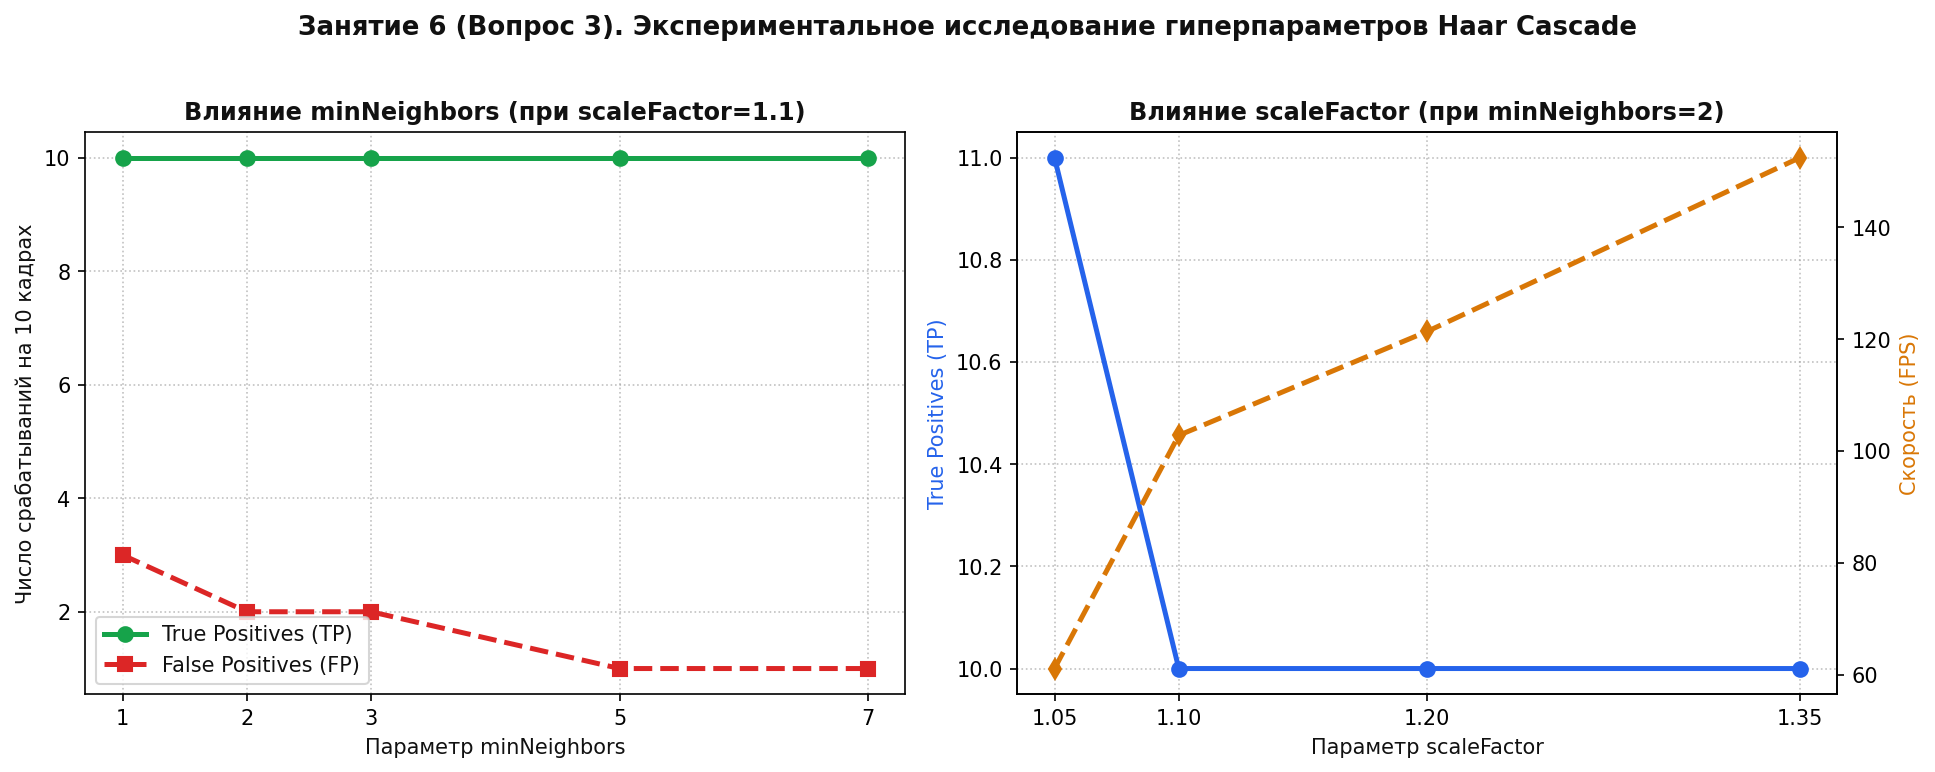

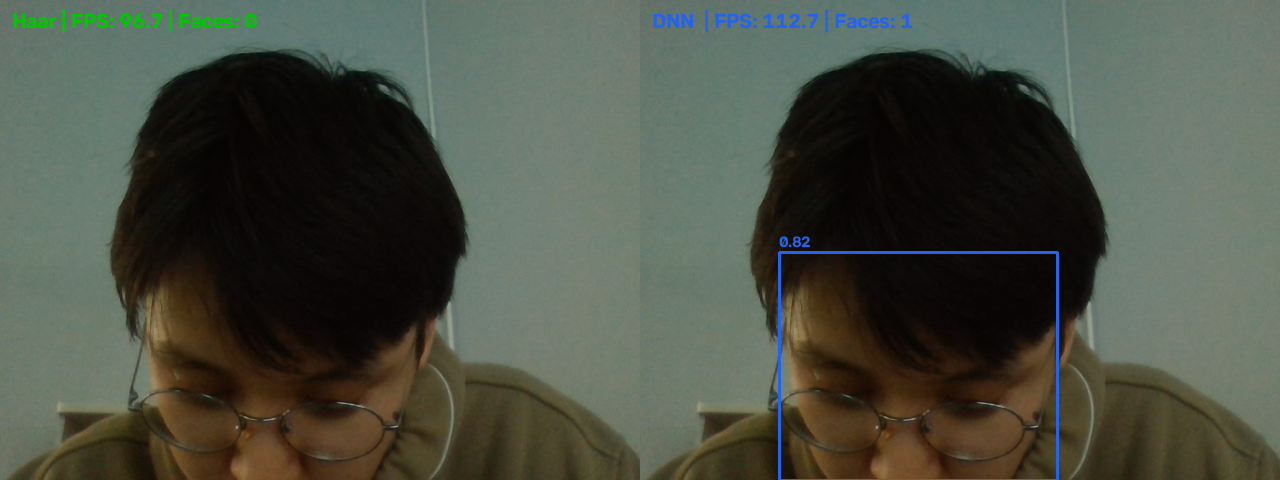

In [3]:
run_haar_params_experiment(face_cascade, dataset_meta)
run_webcam_demo(face_cascade, dnn_net, interactive=False)
display(Image(filename='reports/lab06_haar_params_experiment.png'))
display(Image(filename='reports/lab06_webcam_demo.png'))

## Контрольные вопросы

### 1. В каких условиях Haar Cascade даёт больше false positive, чем DNN?
- На **сложном контрастном или структурном фоне** (оконные решётки, жалюзи, кирпичная кладка, полки, ветви деревьев, узоры на одежде), где чередование горизонтальных и вертикальных тёмных/светлых прямоугольных полос случайно совпадает с конфигурацией примитивов Хаара (например, «тёмная полоса глаз над светлой переносицей»).
- При **малом значении `minNeighbors` ($\le 2$)**, когда единичные случайные срабатывания скользящего окна не отфильтровываются по кучности.

### 2. Почему DNN-детектор в среднем медленнее, но точнее?
- **Почему медленнее:** Каскад Хаара вычисляет простые разности сумм пикселей за $O(1)$ через интегральное изображение (Integral Image) и отбрасывает $>95\%$ фоновых окон уже на первых 2–3 слабых классификаторах. Нейросеть **DNN SSD (ResNet-10)** выполняет десятки миллионов операций умножения-сложения (MAC) в свёрточных слоях по всему изображению $300\times 300$.
- **Почему точнее:** Свёрточные слои извлекают иерархические семантические признаки (от границ до целостной трёхмерной структуры лица), обученные на сотнях тысяч реальных лиц, поэтому DNN устойчива к наклонам и поворотам головы, очкам, частичным перекрытиям и неравномерному освещению.

### 3. Как `minNeighbors` и `scaleFactor` влияют на результат Haar Cascade?
- **`scaleFactor`** (коэффициент масштабирования пирамиды изображений, например `1.05` vs `1.3`): чем ближе к `1.0` (например `1.05`), тем плотнее проверяются масштабы — **растёт полнота (TP)**, но **падает скорость (FPS)** и возрастает число кандидатов. При большом `scaleFactor` (`1.3`) работа ускоряется, но лица промежуточного размера могут быть пропущены (растёт FN).
- **`minNeighbors`** (минимальное число перекрывающихся соседних рамок для подтверждения лица): при малом значении (`1–2`) каскад находит максимум лиц, но даёт **много ложных срабатываний (высокий FP)**. При увеличении (`5–8`) ложные срабатывания полностью исчезают ($\text{FP} \to 0$), но начинают отсеиваться настоящие лица в сложных ракурсах или при слабом освещении (растёт FN).